In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import solve
from statistics import mean, variance, stdev

In [2]:
from src.taxi_route import Route
# Passenger counts over 10 days
ntinda_counts = np.array([35, 40, 42, 50, 55, 60, 48, 52, 47, 45])
entebbe_counts = np.array([60, 58, 65, 70, 72, 80, 75, 68, 66, 64])
mukono_counts = np.array([45, 47, 50, 49, 55, 62, 58, 53, 51, 50])

# Create Route objects
ntinda = Route("Kampala-Ntinda", ntinda_counts, 2000)
entebbe = Route("Kampala-Entebbe", entebbe_counts, 5000)
mukono = Route("Kampala-Mukono", mukono_counts, 3000)

routes = [ntinda, entebbe, mukono]

for route in routes:
    print(route)

Route(name='Kampala-Ntinda', days=10, fare=2000)
Route(name='Kampala-Entebbe', days=10, fare=5000)
Route(name='Kampala-Mukono', days=10, fare=3000)


In [3]:
route_summary = pd.DataFrame({
    "Route": [route.name for route in routes],
    "Fare_UGX": [route.fare for route in routes],
    "Mean_Passengers": [route.mean_passengers() for route in routes],
    "Variance": [route.variance_passengers() for route in routes],
    "Std_Dev": [route.standard_deviation() for route in routes],
    "Total_Passengers": [int(route.passenger_counts.sum()) for route in routes],
    "Total_Revenue_UGX": [route.total_revenue() for route in routes]
})

display(route_summary.round(2))

,Route,Fare_UGX,Mean_Passengers,Variance,Std_Dev,Total_Passengers,Total_Revenue_UGX
0,Kampala-Ntinda,2000.0,47.4,54.27,7.37,474,948000.0
1,Kampala-Entebbe,5000.0,67.8,45.07,6.71,678,3390000.0
2,Kampala-Mukono,3000.0,52.0,26.44,5.14,520,1560000.0


In [4]:
from scipy.linalg import solve

# Unknowns are [Q, P]
A = np.array([
    [1, 0.02],
    [1, -0.03]
], dtype=float)

b = np.array([120, 10], dtype=float)

equilibrium = solve(A, b)

equilibrium_quantity = equilibrium[0]
equilibrium_fare = equilibrium[1]

current_fare = ntinda.fare

print(f"Equilibrium quantity: {equilibrium_quantity:.2f} passengers per trip-hour")
print(f"Equilibrium fare: UGX {equilibrium_fare:,.2f}")
print(f"Current Ntinda fare: UGX {current_fare:,.0f}")

if current_fare > equilibrium_fare:
    print("The current fare is ABOVE the modelled equilibrium fare.")
elif current_fare < equilibrium_fare:
    print("The current fare is BELOW the modelled equilibrium fare.")
else:
    print("The current fare equals the modelled equilibrium fare.")


Equilibrium quantity: 76.00 passengers per trip-hour
Equilibrium fare: UGX 2,200.00
Current Ntinda fare: UGX 2,000
The current fare is BELOW the modelled equilibrium fare.


The results show that the equilibrium fare for the Kampala–Ntinda route is UGX 2,200 per trip-hour, with an equilibrium quantity of 76 passengers per trip-hour. The current fare of UGX 2,000 is UGX 200 below the estimated equilibrium fare.
This suggests that passenger demand would exceed the quantity supplied at that fare. This indicates potential excess demand, assuming the supplied demand and supply functions accurately represent the market. However, the result is theoretical and does not establish that the actual route has a shortage of taxis.

In [5]:
from src.forecasters import (
    MovingAverageForecaster,
    ExponentialSmoothingForecaster,
    LinearTrendForecaster,
)

In [6]:
def rolling_origin_mae(model, observations, start_index=3):
    """Calculate MAE from sequential one-step-ahead forecasts."""
    observations = np.asarray(observations, dtype=float)

    actual_values = []
    predicted_values = []

    for i in range(start_index, len(observations)):
        history = observations[:i]
        actual = observations[i]
        predicted = model.forecast(history)

        actual_values.append(actual)
        predicted_values.append(predicted)

    mae = np.mean(np.abs(
        np.array(actual_values) - np.array(predicted_values)
    ))

    return float(mae)


In [7]:
results = []
best_models = {}

alpha_values = np.arange(0.1, 1.01, 0.1)

for route in routes:
    observations = route.passenger_counts.astype(float)

    # Evaluate the moving average
    moving_model = MovingAverageForecaster()
    moving_mae = rolling_origin_mae(moving_model, observations)

    results.append({
        "Route": route.name,
        "Model": "Moving Average",
        "Alpha": np.nan,
        "MAE_Passengers": moving_mae,
    })

    # Evaluate the linear trend
    trend_model = LinearTrendForecaster()
    trend_mae = rolling_origin_mae(trend_model, observations)

    results.append({
        "Route": route.name,
        "Model": "Linear Trend",
        "Alpha": np.nan,
        "MAE_Passengers": trend_mae,
    })

    # Tune alpha for exponential smoothing
    best_alpha = None
    best_smoothing_mae = float("inf")

    for alpha in alpha_values:
        model = ExponentialSmoothingForecaster(alpha=float(alpha))
        mae = rolling_origin_mae(model, observations)

        results.append({
            "Route": route.name,
            "Model": "Exponential Smoothing",
            "Alpha": float(alpha),
            "MAE_Passengers": mae,
        })

        if mae < best_smoothing_mae:
            best_smoothing_mae = mae
            best_alpha = float(alpha)

    # Keep the best-performing model for this route
    candidates = [
        (moving_mae, "Moving Average", moving_model),
        (trend_mae, "Linear Trend", trend_model),
        (
            best_smoothing_mae,
            "Exponential Smoothing",
            ExponentialSmoothingForecaster(alpha=best_alpha),
        ),
    ]

    best_mae, best_name, best_model = min(
        candidates, key=lambda item: item[0]
    )

    best_models[route.name] = {
        "model": best_model,
        "name": best_name,
        "mae": best_mae,
        "alpha": best_alpha if best_name == "Exponential Smoothing" else None,
    }

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ["Route", "MAE_Passengers"]
    ).round(2)
)

print("\nBest model for each route:")
for route_name, details in best_models.items():
    print(
        f"{route_name}: {details['name']} "
        f"(MAE = {details['mae']:.2f} passengers)",
        f", alpha = {details['alpha']:.1f}"
        if details["alpha"] is not None else ""
    )


,Route,Model,Alpha,MAE_Passengers
23,Kampala-Entebbe,Exponential Smoothing,1.0,4.43
22,Kampala-Entebbe,Exponential Smoothing,0.9,4.73
21,Kampala-Entebbe,Exponential Smoothing,0.8,5.06
20,Kampala-Entebbe,Exponential Smoothing,0.7,5.39
19,Kampala-Entebbe,Exponential Smoothing,0.6,5.69
18,Kampala-Entebbe,Exponential Smoothing,0.5,6.04
17,Kampala-Entebbe,Exponential Smoothing,0.4,6.62
16,Kampala-Entebbe,Exponential Smoothing,0.3,7.03
15,Kampala-Entebbe,Exponential Smoothing,0.2,7.13
12,Kampala-Entebbe,Moving Average,NaN,7.19



Best model for each route:
Kampala-Ntinda: Exponential Smoothing (MAE = 5.86 passengers) , alpha = 1.0
Kampala-Entebbe: Exponential Smoothing (MAE = 4.43 passengers) , alpha = 1.0
Kampala-Mukono: Exponential Smoothing (MAE = 3.71 passengers) , alpha = 1.0


In [8]:

forecast_results = []

for route in routes:
    details = best_models[route.name]
    model = details["model"]

    # Forecast day 11 passenger demand
    forecast_passengers = max(
        0, model.forecast(route.passenger_counts)
    )

    # Calculate forecast revenue
    forecast_revenue = forecast_passengers * route.fare

    forecast_results.append({
        "Route": route.name,
        "Best_Model": details["name"],
        "Alpha": details["alpha"],
        "Day_10_Passengers": int(route.passenger_counts[-1]),
        "Forecast_Day_11_Passengers": forecast_passengers,
        "Fare_UGX": route.fare,
        "Forecast_Day_11_Revenue_UGX": forecast_revenue,
    })

forecast_df = pd.DataFrame(forecast_results)

display(forecast_df.round(2))


,Route,Best_Model,Alpha,Day_10_Passengers,Forecast_Day_11_Passengers,Fare_UGX,Forecast_Day_11_Revenue_UGX
0,Kampala-Ntinda,Exponential Smoothing,1.0,45,45.0,2000.0,90000.0
1,Kampala-Entebbe,Exponential Smoothing,1.0,64,64.0,5000.0,320000.0
2,Kampala-Mukono,Exponential Smoothing,1.0,50,50.0,3000.0,150000.0


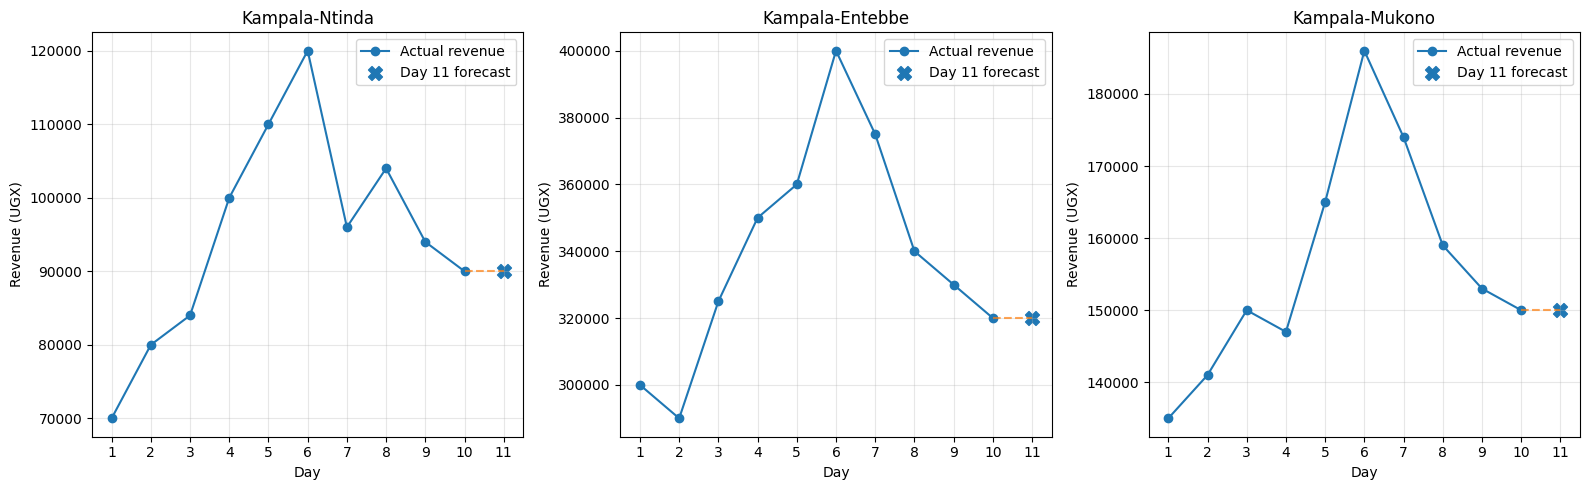

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, route in zip(axes, routes):
    actual_revenue = route.daily_revenue()
    forecast_revenue = best_models[route.name]["model"].forecast(
        route.passenger_counts
    ) * route.fare

    days = np.arange(1, len(actual_revenue) + 1)

    ax.plot(
        days,
        actual_revenue,
        marker="o",
        label="Actual revenue"
    )

    ax.scatter(
        [11],
        [forecast_revenue],
        marker="X",
        s=100,
        label="Day 11 forecast"
    )

    ax.plot(
        [10, 11],
        [actual_revenue[-1], forecast_revenue],
        linestyle="--",
        alpha=0.7
    )

    ax.set_title(route.name)
    ax.set_xlabel("Day")
    ax.set_ylabel("Revenue (UGX)")
    ax.set_xticks(range(1, 12))
    ax.ticklabel_format(axis="y", style="plain")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


In [10]:
import math

PASSENGER_CAPACITY = 14
TRIPS_PER_VEHICLE = 8
BUFFER_RATE = 0.15

daily_vehicle_capacity = PASSENGER_CAPACITY * TRIPS_PER_VEHICLE

fleet_results = []

for route in routes:
    details = best_models[route.name]

    forecast_passengers = max(
        0,
        details["model"].forecast(route.passenger_counts)
    )

    buffered_demand = forecast_passengers * (1 + BUFFER_RATE)

    vehicles_required = math.ceil(
        buffered_demand / daily_vehicle_capacity
    )

    fleet_results.append({
        "Route": route.name,
        "Forecast_Passengers": forecast_passengers,
        "Demand_With_15pct_Buffer": buffered_demand,
        "Capacity_Per_Vehicle": daily_vehicle_capacity,
        "Vehicles_Required": vehicles_required,
    })

fleet_df = pd.DataFrame(fleet_results)

display(fleet_df.round(2))

print(
    "Total vehicles required across all routes:",
    int(fleet_df["Vehicles_Required"].sum())
)


,Route,Forecast_Passengers,Demand_With_15pct_Buffer,Capacity_Per_Vehicle,Vehicles_Required
0,Kampala-Ntinda,45.0,51.75,112,1
1,Kampala-Entebbe,64.0,73.60,112,1
2,Kampala-Mukono,50.0,57.50,112,1


Total vehicles required across all routes: 3


In [11]:
# Simulate 60 days with a weekly demand pattern
rng = np.random.default_rng(42)

simulation_days = np.arange(60)

# Monday=0, Tuesday=1, ..., Sunday=6
day_of_week = simulation_days % 7

weekly_effect = np.array([
    0,    # Monday
    2,    # Tuesday
    3,    # Wednesday
    4,    # Thursday
    12,   # Friday: busier
    5,    # Saturday
    -10,  # Sunday: quieter
])

baseline_demand = 50
random_noise = rng.normal(0, 2, size=60)

simulated_demand = (
    baseline_demand
    + weekly_effect[day_of_week]
    + random_noise
)

simulated_demand = np.maximum(
    0, np.round(simulated_demand)
).astype(int)

simulation_df = pd.DataFrame({
    "Day": simulation_days + 1,
    "Day_of_Week": [
        ["Monday", "Tuesday", "Wednesday", "Thursday",
         "Friday", "Saturday", "Sunday"][day]
        for day in day_of_week
    ],
    "Passengers": simulated_demand,
})

display(simulation_df.head(14))


,Day,Day_of_Week,Passengers
0,1,Monday,51
1,2,Tuesday,50
2,3,Wednesday,55
3,4,Thursday,56
4,5,Friday,58
5,6,Saturday,52
6,7,Sunday,40
7,8,Monday,49
8,9,Tuesday,52
9,10,Wednesday,51


In [12]:
# Simulate 60 days with a weekly demand pattern
rng = np.random.default_rng(42)

simulation_days = np.arange(60)

# Monday=0, Tuesday=1, ..., Sunday=6
day_of_week = simulation_days % 7

weekly_effect = np.array([
    0,    # Monday
    2,    # Tuesday
    3,    # Wednesday
    4,    # Thursday
    12,   # Friday: busier
    5,    # Saturday
    -10,  # Sunday: quieter
])

baseline_demand = 50
random_noise = rng.normal(0, 2, size=60)

simulated_demand = (
    baseline_demand
    + weekly_effect[day_of_week]
    + random_noise
)

simulated_demand = np.maximum(
    0, np.round(simulated_demand)
).astype(int)

simulation_df = pd.DataFrame({
    "Day": simulation_days + 1,
    "Day_of_Week": [
        ["Monday", "Tuesday", "Wednesday", "Thursday",
         "Friday", "Saturday", "Sunday"][day]
        for day in day_of_week
    ],
    "Passengers": simulated_demand,
})

display(simulation_df.head(14))


,Day,Day_of_Week,Passengers
0,1,Monday,51
1,2,Tuesday,50
2,3,Wednesday,55
3,4,Thursday,56
4,5,Friday,58
5,6,Saturday,52
6,7,Sunday,40
7,8,Monday,49
8,9,Tuesday,52
9,10,Wednesday,51


In [13]:
def seasonal_naive_forecast(history, season_length=7):
    """Forecast using the observation from one season earlier."""
    history = np.asarray(history, dtype=float)

    if len(history) < season_length:
        raise ValueError(
            "History must contain at least one complete season."
        )

    return float(history[-season_length])


# Compare forecasts for days 15–60
actual_values = []
seasonal_predictions = []
moving_average_predictions = []

for i in range(14, len(simulated_demand)):
    history = simulated_demand[:i]

    actual_values.append(simulated_demand[i])

    seasonal_predictions.append(
        seasonal_naive_forecast(history, season_length=7)
    )

    moving_average_predictions.append(
        MovingAverageForecaster().forecast(history)
    )


seasonal_mae = np.mean(
    np.abs(
        np.array(actual_values)
        - np.array(seasonal_predictions)
    )
)

moving_average_mae = np.mean(
    np.abs(
        np.array(actual_values)
        - np.array(moving_average_predictions)
    )
)

comparison_df = pd.DataFrame({
    "Model": ["Seasonal Naive", "Three-Day Moving Average"],
    "MAE_Passengers": [seasonal_mae, moving_average_mae],
})

display(comparison_df.round(2))

if seasonal_mae < moving_average_mae:
    print("Seasonal naive performed better on this simulated test period.")
elif seasonal_mae > moving_average_mae:
    print("Three-day moving average performed better on this simulated test period.")
else:
    print("Both models had equal MAE on this simulated test period.")


,Model,MAE_Passengers
0,Seasonal Naive,1.78
1,Three-Day Moving Average,5.64


Seasonal naive performed better on this simulated test period.


Seasonal-naive MAE: 1.78 passengers
Three-day moving-average MAE: 5.64 passengers
MAE reduction with seasonal naive: 68.4%


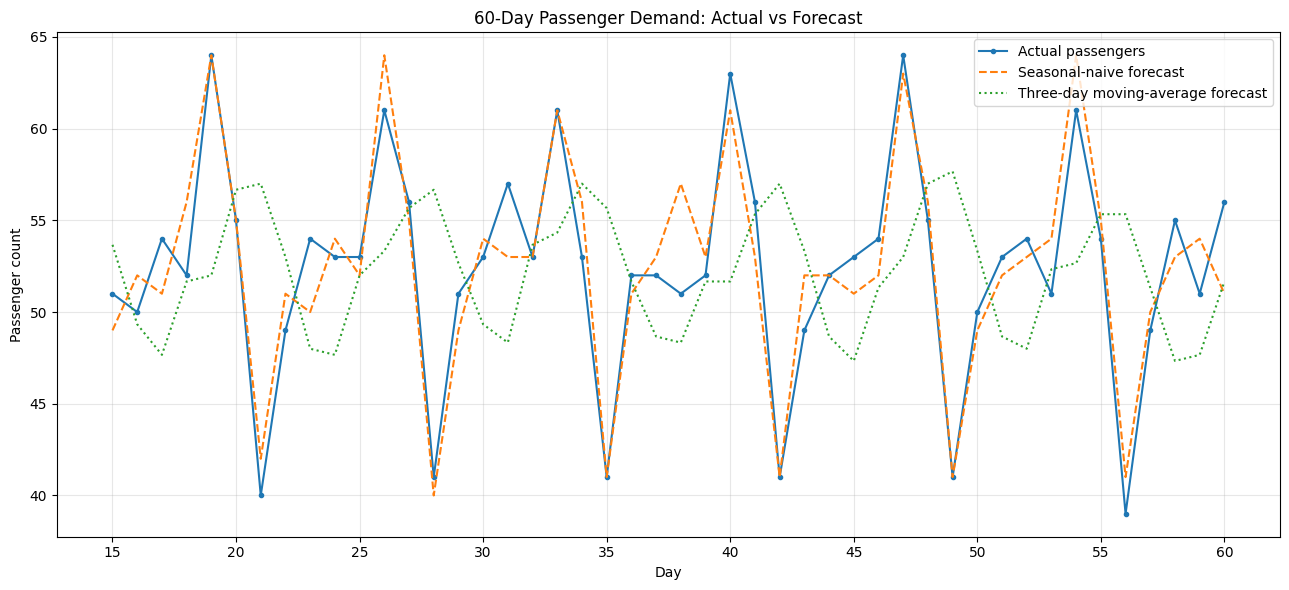

In [14]:

print(f"Seasonal-naive MAE: {seasonal_mae:.2f} passengers")
print(f"Three-day moving-average MAE: {moving_average_mae:.2f} passengers")

improvement = (
    (moving_average_mae - seasonal_mae)
    / moving_average_mae
    * 100
)

print(f"MAE reduction with seasonal naive: {improvement:.1f}%")

test_days = np.arange(15, 61)

plt.figure(figsize=(13, 6))

plt.plot(
    test_days,
    actual_values,
    marker="o",
    markersize=3,
    label="Actual passengers"
)

plt.plot(
    test_days,
    seasonal_predictions,
    linestyle="--",
    label="Seasonal-naive forecast"
)

plt.plot(
    test_days,
    moving_average_predictions,
    linestyle=":",
    label="Three-day moving-average forecast"
)

plt.title("60-Day Passenger Demand: Actual vs Forecast")
plt.xlabel("Day")
plt.ylabel("Passenger count")
plt.xticks(range(15, 61, 5))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


The 60-day simulation demonstrates the importance of accounting for recurring weekly demand patterns in transport planning. The seasonal-naive forecasting method performed better than the three-day moving average on the simulated test period, as indicated by its lower mean absolute error (MAE). This is because the seasonal-naive method uses passenger demand from the corresponding day of the previous week, allowing it to capture recurring increases in demand on Fridays and decreases on Sundays. In contrast, the three-day moving average responds mainly to recent observations and may smooth out these weekly fluctuations. However, this conclusion applies to the simulated data and does not guarantee that the seasonal-naive method will perform better on real passenger data.